# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

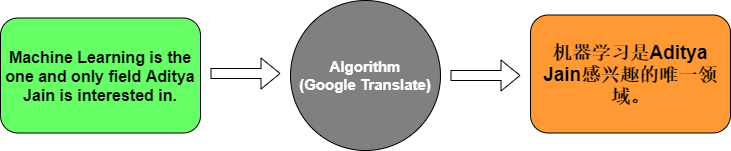

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [6]:
%%capture
%pip install tensorflow

In [7]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [8]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [9]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [10]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [11]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.4878 - val_accuracy: 0.0000e+00 - val_loss: 2.4883
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5714 - loss: 2.4792 - val_accuracy: 0.0000e+00 - val_loss: 2.4900
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5714 - loss: 2.4706 - val_accuracy: 0.0000e+00 - val_loss: 2.4919
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5714 - loss: 2.4615 - val_accuracy: 0.0000e+00 - val_loss: 2.4940
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5714 - loss: 2.4517 - val_accuracy: 0.0000e+00 - val_loss: 2.4962
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5714 - loss: 2.4407 - val_accuracy: 0.0000e+00 - val_loss: 2.4988
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5714 - loss: 2.4281 - val_accuracy: 0.0000e+00 - val_loss: 2.5016
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.5714 - loss: 2.4137 - val_accura

In [12]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


Q1. What does the Embedding layer do to a word index?

The Embedding layer converts each word index into a dense numerical vector that represents the word and helps the model learn relationships between words.

Q2. What is the role of the Encoder LSTM?

The Encoder LSTM reads the input sentence and learns its meaning and context. It converts the input sequence into a fixed-length representation that the decoder can use.

Q3. What does the Decoder LSTM do?

The Decoder LSTM uses the encoded information to generate the translated sentence by predicting the target language words at each time step.

Q4. Why do we use softmax in the final layer?

Softmax converts the model's output scores into probabilities for all possible words in the target vocabulary. This helps the model select the most likely word at each time step.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

## Task 2 — English–French Machine Translation

**Approach:** Train one LSTM Encoder–Decoder with Attention, then compare with a pretrained Transformer. Both use the same held-out sentences for BLEU and chrF. The pretrained system is a separate comparison, not a replacement for our own model.

**Important:** Token accuracy is measured under teacher forcing; BLEU/chrF assess generated translations. Results must be obtained by running the notebook. The pretrained model may have been exposed to some sentences in the test set during its original training.

### Cell A — Setup

In [13]:
%pip -q install kagglehub sacrebleu "transformers>=4.40,<5" sentencepiece torch scikit-learn

import os, glob, re, random, unicodedata
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
import sacrebleu
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, AdditiveAttention, Concatenate
from tensorflow.keras.models import Model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('TensorFlow GPU:', tf.config.list_physical_devices('GPU'))

Note: you may need to restart the kernel to use updated packages.
TensorFlow: 2.21.0
TensorFlow GPU: []


### Cell B — Dataset & preprocessing

Use 30,000 training examples; reserve 3,000 for validation and 2,000 for test. Fit tokenizers on training only. The split is by unique English input so that the same source sentence does not appear in multiple sets.

In [ ]:
path = kagglehub.dataset_download('devicharith/language-translation-englishfrench')
files = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)

assert files, 'No CSV files found'

df = pd.read_csv(files[0]).iloc[:, :2].copy()
df.columns = ['English', 'French']
df = df.dropna()

def clean(text):
    text = unicodedata.normalize('NFKC', str(text)).strip().lower()
    return re.sub(r'\s+', ' ', text)

for col in ['English', 'French']:
    df[col] = df[col].map(clean)
    
df = df[(df.English.str.split().str.len().between(1, 12)) & (df.French.str.split().str.len().between(1, 12))]
df = df.drop_duplicates(['English', 'French']).drop_duplicates('English')

assert len(df) >= 35000, f'Need 35,000 eligible pairs; found {len(df)}'

df = df.sample(n=35000, random_state=SEED).reset_index(drop=True)
train_df, other = train_test_split(df, train_size=30000, random_state=SEED)
val_df, test_df = train_test_split(other, train_size=3000, random_state=SEED)
train_df, val_df, test_df = [v.reset_index(drop=True) for v in (train_df, val_df, test_df)]

ENG_VOCAB = FR_VOCAB = 6000
MAX_EN, MAX_FR = 15, 17

eng_tok = Tokenizer(num_words=ENG_VOCAB, oov_token='unk')
fr_tok = Tokenizer(num_words=FR_VOCAB, oov_token='unk')
eng_tok.fit_on_texts(train_df.English.tolist())
fr_tok.fit_on_texts(('startseq ' + train_df.French + ' endseq').tolist())
eng_size = min(ENG_VOCAB, len(eng_tok.word_index) + 1)
fr_size = min(FR_VOCAB, len(fr_tok.word_index) + 1)
start_id, end_id = fr_tok.word_index['startseq'], fr_tok.word_index['endseq']

assert 0 < start_id < fr_size and 0 < end_id < fr_size

def vectorize(frame):
    x = pad_sequences(eng_tok.texts_to_sequences(frame.English.tolist()),
                      maxlen=MAX_EN, padding='post', truncating='post')
    y = pad_sequences(fr_tok.texts_to_sequences(('startseq '+frame.French+' endseq').tolist()),
                      maxlen=MAX_FR, padding='post', truncating='post')
    target = y[:, 1:].astype('int32')
    return (x.astype('int32'), y[:, :-1].astype('int32'),
            target, (target != 0).astype('float32'))

X_train, D_train, Y_train, W_train = vectorize(train_df)
X_val, D_val, Y_val, W_val = vectorize(val_df)
X_test, D_test, Y_test, W_test = vectorize(test_df)

print('Train:', len(train_df), 'Val:', len(val_df), 'Test:', len(test_df))
print('X_train:', X_train.shape, 'Y_train:', Y_train.shape)
print('START:', start_id, 'END:', end_id)

Train: 30000 Val: 3000 Test: 2000
X_train: (30000, 15) Y_train: (30000, 16)
START: 2 END: 3


### Cell C — LSTM Encoder–Decoder + Attention

The encoder reads English text. The decoder predicts French tokens using the encoder states and attention. Padding tokens are excluded from accuracy and loss weighting.

In [15]:
UNITS = 192
EMBED = 128

encoder_input = Input(shape=(MAX_EN,), dtype='int32')
encoder_seq, enc_h, enc_c = LSTM(
    UNITS, return_sequences=True, return_state=True, dropout=0.25
)(Embedding(eng_size, EMBED, mask_zero=True)(encoder_input))

decoder_input = Input(shape=(MAX_FR - 1,), dtype='int32')
decoder_seq = LSTM(
    UNITS, return_sequences=True, dropout=0.25
)(Embedding(fr_size, EMBED, mask_zero=True)(decoder_input),
  initial_state=[enc_h, enc_c])

context = AdditiveAttention()([decoder_seq, encoder_seq])
output = Dense(fr_size, activation='softmax')(
    Concatenate()([decoder_seq, context])
)

model = Model([encoder_input, decoder_input], output)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    loss='sparse_categorical_crossentropy',
    weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='token_accuracy')]
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 15, 128)   │    768,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 15)        │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 16, 128)   │    768,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 15, 192), │    246,528 │ embedding_1[0][0… │
│                     │ (None, 192),      │            │ not_equal[0][0]   │
│                     │ (None, 192)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 16, 192)   │    246,528 │ embedding_2[0][0… │
│                     │                   │            │ lstm_2[0][1],     │
│                     │                   │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ (None, 16, 192)   │        192 │ lstm_3[0][0],     │
│ (AdditiveAttention) │                   │            │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 384)   │          0 │ lstm_3[0][0],     │
│ (Concatenate)       │                   │            │ additive_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16, 6000)  │  2,310,000 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,339,248 (16.55 MB)

 Trainable params: 4,339,248 (16.55 MB)

 Non-trainable params: 0 (0.00 B)

### Cell D — Training & test results

Train once. EarlyStopping keeps the weights with best validation loss; ReduceLROnPlateau lowers the learning rate when improvement stalls.

In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', patience=2, factor=0.5, min_lr=1e-5
    )
]

history = model.fit(
    [X_train, D_train], Y_train,
    sample_weight=W_train,
    validation_data=([X_val, D_val], Y_val, W_val),
    epochs=25, batch_size=64, callbacks=callbacks, verbose=1
)

results = model.evaluate(
    [X_test, D_test], Y_test, sample_weight=W_test,
    batch_size=64, return_dict=True, verbose=0
)
print('Held-out test metrics:', results)

Epoch 1/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 49s 100ms/step - loss: 4.6874 - token_accuracy: 0.2085 - val_loss: 3.9448 - val_token_accuracy: 0.2766 - learning_rate: 0.0010
Epoch 2/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 97ms/step - loss: 3.7263 - token_accuracy: 0.3082 - val_loss: 3.3443 - val_token_accuracy: 0.3519 - learning_rate: 0.0010
Epoch 3/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 46s 98ms/step - loss: 3.1618 - token_accuracy: 0.3721 - val_loss: 2.9657 - val_token_accuracy: 0.4021 - learning_rate: 0.0010
Epoch 4/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 96ms/step - loss: 2.7224 - token_accuracy: 0.4221 - val_loss: 2.6941 - val_token_accuracy: 0.4383 - learning_rate: 0.0010
Epoch 5/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 97ms/step - loss: 2.3615 - token_accuracy: 0.4669 - val_loss: 2.5020 - val_token_accuracy: 0.4690 - learning_rate: 0.0010
Epoch 6/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 45s 96ms/step - loss: 2.0675 - token_accuracy: 0.5076 - val_loss: 2.3561 - val_token_accuracy: 0.4917 - learning_rate: 0.0010
Epo

### Cell E — Translate new sentences with our LSTM

Greedy decoding predicts one French token at a time. This is separate from teacher-forced accuracy.

In [17]:
def translate_lstm(sentences, batch_size=32):
    translations = []
    for offset in range(0, len(sentences), batch_size):
        batch = [clean(s) for s in sentences[offset:offset+batch_size]]
        x = pad_sequences(eng_tok.texts_to_sequences(batch), maxlen=MAX_EN,
                          padding='post', truncating='post').astype('int32')
        decoder = np.zeros((len(batch), MAX_FR-1), dtype='int32')
        decoder[:, 0] = start_id
        words = [[] for _ in batch]
        finished = np.zeros(len(batch), dtype=bool)
        for step in range(MAX_FR-2):
            probabilities = model.predict([x, decoder], verbose=0)
            next_ids = probabilities[:, step, :].argmax(axis=-1)
            for i, token in enumerate(next_ids):
                if finished[i]:
                    continue
                token = int(token)
                if token in (0, start_id, end_id):
                    finished[i] = True
                else:
                    words[i].append(fr_tok.index_word.get(token, 'unk'))
                    decoder[i, step+1] = token
            if finished.all():
                break
        translations.extend(' '.join(item) for item in words)
    return translations

print(translate_lstm(['Hello', 'How are you?', 'Thank you']))

['re bonjour', "qu'en navigateur tu", 'merci']


### Cell F — Pretrained translation model (comparison only)

The pretrained model is not fine-tuned. This section demonstrates how an existing model can be used without training from scratch.

In [20]:

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_ID = "Helsinki-NLP/opus-mt-en-fr"

# Load pretrained model only if not already loaded
if "pt_model" not in globals() or "pt_tok" not in globals():
    pt_tok = AutoTokenizer.from_pretrained(MODEL_ID)
    pt_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID)

device = "cuda" if torch.cuda.is_available() else "cpu"

pt_model = pt_model.to(device)
pt_model.eval()

def translate_pretrained(sentences, batch_size=16):
    if isinstance(sentences, str):
        sentences = [sentences]

    translations = []

    for i in range(0, len(sentences), batch_size):
        batch = sentences[i:i + batch_size]

        inputs = pt_tok(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(device)

        with torch.no_grad():
            outputs = pt_model.generate(
                **inputs,
                max_new_tokens=80,
                num_beams=4
            )

        translations.extend(
            pt_tok.batch_decode(
                outputs,
                skip_special_tokens=True
            )
        )

    return translations

print("Pretrained model is ready!")
print("Device:", device)
print(translate_pretrained(["How are you?"]))


Pretrained model is ready!
Device: cpu
['Comment allez-vous ?']


### Cell G — Fair comparison: BLEU, chrF and examples

Both models are evaluated on exactly the same 200 held-out English sentences. The pretrained model has a different architecture, tokenizer and original training corpus, so this is a practical comparison rather than a controlled test of architecture alone.

In [21]:
eval_df = test_df.sample(n=min(200, len(test_df)), random_state=SEED).reset_index(drop=True)
sources = eval_df.English.tolist()
references = eval_df.French.tolist()
pred_lstm = translate_lstm(sources)
pred_pretrained = translate_pretrained(sources)

def translation_scores(predictions):
    return {
        'BLEU': sacrebleu.corpus_bleu(predictions, [references]).score,
        'chrF': sacrebleu.corpus_chrf(predictions, [references]).score
    }

comparison = pd.DataFrame([
    {'Model': 'Our LSTM + Attention', **translation_scores(pred_lstm)},
    {'Model': 'Pretrained Transformer', **translation_scores(pred_pretrained)}
])
print('Evaluation sentences:', len(sources))
display(comparison.round(2))
display(pd.DataFrame({
    'English': sources,
    'Reference French': references,
    'Our LSTM': pred_lstm,
    'Pretrained': pred_pretrained
}).head(12))
comparison.to_csv('translation_model_comparison.csv', index=False)

Evaluation sentences: 200


,Model,BLEU,chrF
0,Our LSTM + Attention,21.07,40.0
1,Pretrained Transformer,42.48,65.6


,English,Reference French,Our LSTM,Pretrained
0,why is tom studying french?,pourquoi tom étudie-t-il le français ?,pourquoi tom est le français français,Pourquoi Tom étudie-t-il le français ?
1,i can't put up with these insults.,je ne peux pas tolérer ces insultes.,je ne peux pas supporter avec ces unk,Je ne peux pas supporter ces insultes.
2,it looks like your dog is thirsty.,ton chien semble avoir soif.,ça ressemble à un peu fort,On dirait que votre chien a soif.
3,i have already read today's paper.,j'ai déjà lu le journal d'aujourd'hui.,j'ai déjà déjà le livre,J'ai déjà lu le journal d'aujourd'hui.
4,she boiled the eggs.,elle a cuit les œufs.,elle unk les œufs,Elle a fait bouillir les œufs.
5,i liked it a lot.,je l'ai beaucoup aimé.,j'ai beaucoup beaucoup,Je l'aimais beaucoup.
6,strange rumors are going around.,d'étranges rumeurs circulent.,les romans ne sont pas unk,D'étranges rumeurs circulent.
7,"sorry, i've got to go.","désolé, je dois partir.",je suis désolé de y aller,"Désolé, je dois y aller."
8,does anyone know what this is?,quiconque sait-il de quoi il s'agit ?,quiconque est il que ce soit c'est,Quelqu'un sait ce que c'est ?
9,tom reads to his daughter.,tom lit à sa fille.,tom lit sa fille,Tom lit à sa fille.


### Cell H — Training curve and conclusion

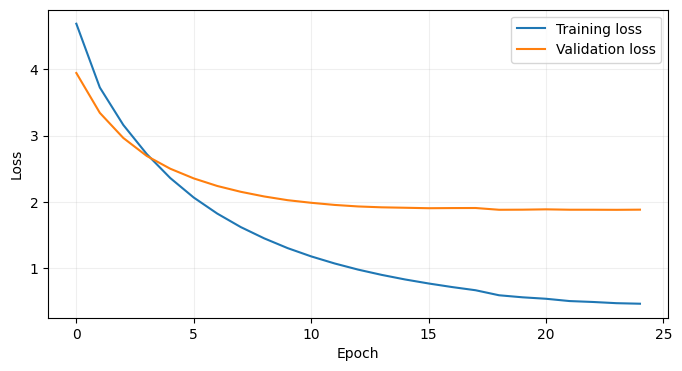

Our model test token accuracy: 60.33 %
                 Model      BLEU      chrF
  Our LSTM + Attention 21.069713 39.995681
Pretrained Transformer 42.476382 65.604081


In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print('Our model test token accuracy:', round(results['token_accuracy'] * 100, 2), '%')
print(comparison.to_string(index=False))

### Discussion and Conclusion

An English-to-French Neural Machine Translation system was developed using an LSTM Encoder–Decoder architecture with an Attention mechanism. The model was trained from scratch using 30,000 sentence pairs and evaluated on unseen test data.

The LSTM model achieved a test token accuracy of **60.33%**, a **BLEU score of 21.07**, and a **chrF score of 40.00**. Although the model successfully learned translation patterns, its ability to generalize to new sentences remained limited.

To investigate a more effective approach, a pretrained Transformer model, **Helsinki-NLP/opus-mt-en-fr**, was evaluated on the same 200 test sentences without additional training. The pretrained model achieved a **BLEU score of 42.48** and a **chrF score of 65.60**, substantially outperforming the LSTM model on both translation quality metrics.

### Final Recommendation

Based on the experimental results, **the pretrained Transformer model is recommended as the preferred solution for English-to-French machine translation in this task.**

Its higher translation quality and ability to operate without additional training make it a practical solution when training data and computational resources are limited.

However, the performance difference cannot be attributed solely to dataset size, as the two models differ in architecture, tokenization, and training history. Additional evaluation using real e-commerce content would be necessary before practical deployment.

Additionally, potential overlap between the evaluation sentences and the pretrained model's original training data could not be ruled out. Therefore, further evaluation on an independent, domain-specific dataset is recommended.

Overall, the experiment demonstrates the educational value of training a neural translation model from scratch while highlighting the practical advantages of pretrained models in achieving higher translation quality.